# Experimental Notebook - Topology scAGCL Model

Source code of `scAGCL` can be found in [levinhcntt/scAGCL](https://github.com/levinhcntt/scAGCL)

## About this notebook

In this notebook, we rerun the experiments introduced in paper "scAGCL: Deep clustering of single-cell RNA-seq using Adversarial Graph Contrastive Learning" and compare with the new version of adding topology-refinement between two augmented views and two adversarial views.

## Load library

In [10]:
import os
import sys
import h5py
import numpy as np
import torch
import random
from torch_geometric.data import Data
from scipy.spatial.distance import pdist, squareform
from sklearn.neighbors import NearestNeighbors
import networkx as nx

sys.path.append(os.path.abspath('..'))

## Setup the params here

In [11]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# device = torch.device('mps' if torch.backends.mps.is_available() else device)

# Max dimension for topological features (0 for connected components, 1 for loops)
MAX_TOPOLOGY_DIM = 1

BASE_DIR = '../../data'
dataset = 'QS_Diaphragm'

num_epochs = 5
topology_epochs = 2
TOPO_WEIGHT = 2000

# 1. Module Code

## 1.1 Preprocessing

In [12]:
import scanpy as sc
from utils.preprocessing import normalize
from sklearn.preprocessing import LabelEncoder

def normalization(features_):
    features = features_.copy()
    for i in range(len(features)):
        features[i] = features[i] / sum(features[i]) * 100000
    features = np.log2(features + 1)
    return features

def preprocess(X, nb_genes = 2000):
    """
    Preprocessing phase as proposed in scanpy package. Keeps only nb_genes most variable genes and normalizes the data to 0 mean and 1 std.
    """

    print("There are " + str(X.shape[0]) + " cells, " + str(X.shape[1]) + " genes")
    print("Data Preprocessing!")
    
    adata = sc.AnnData(X)

    adata = normalize(adata,
                      copy=True,
                      highly_genes=nb_genes,
                      size_factors=True,
                      normalize_input=True,
                      logtrans_input=True)
    X = adata.X.astype('float32')
    print(f"Keeping {nb_genes} genes")
    return X

def load_h5_data1(data_path):
    print("Reading data!")
    inputFile = h5py.File(data_path, 'r')
   
    X = np.array(inputFile['X']).astype('float32')
    Y = np.array(inputFile['Y'])

    if Y.dtype != "int64":
        encoder_x = LabelEncoder()
        Y = encoder_x.fit_transform(Y)
    inputFile.close()
    
    X=preprocess(X, nb_genes=2000)
    return X, Y

def GraphConstruction(data, features, num_clusters):
    cell_num = features.shape[0]
    average_num = cell_num // num_clusters
    neighbor_num = average_num // 10
    neighbor_num = min(neighbor_num, 15)
    neighbor_num = max(neighbor_num, 5)
 
    # Calculate Pearson distance matrix
    dis_matrix = squareform(pdist(features, metric='correlation'))
    # Build kNN graph
    nbrs = NearestNeighbors(n_neighbors=neighbor_num, metric='precomputed').fit(dis_matrix)
    _, indices = nbrs.kneighbors(dis_matrix)  # Get only indices
 
    # Create adjacency matrix
    n_samples = features.shape[0]
    adj_matrix = np.zeros((n_samples, n_samples))

    for i in range(n_samples):
        for j in indices[i]:
             adj_matrix[i, j] = 1  

      
    #Create a list of egdes
    edge_list = torch.empty((2,0), dtype=torch.int64)
    for i in range( adj_matrix.shape[0]):
     for j in range(i + 1,   adj_matrix.shape[1]):
        if  adj_matrix[i, j] == 1:
            col = torch.tensor([i, j], dtype=torch.int64)
            edge_list = torch.cat((edge_list, col.unsqueeze(1)), dim=1)
    data.edge_index=edge_list
          
    #generate a graph
    G = nx.from_numpy_array(adj_matrix)
    print("Building a " + str(G))
    print("===================================================")

    return G

## 1.2 Model Architecture

In [13]:
from torch import nn
from torch.nn import Module, Parameter
import math
import torch.nn.functional as F

class GCNConv(Module):
    def __init__(self, in_features, out_features, bias=True):
        super(GCNConv, self).__init__()
        self.in_features = in_features
        self.out_features = out_features
        self.weight = Parameter(torch.FloatTensor(in_features, out_features))
        if bias:
            self.bias = Parameter(torch.FloatTensor(out_features))
        else:
            self.register_parameter('bias', None)
        self.reset_parameters()

    def reset_parameters(self):
        stdv = 1. / math.sqrt(self.weight.size(1))
        self.weight.data.uniform_(-stdv, stdv)
        if self.bias is not None:
            self.bias.data.uniform_(-stdv, stdv)

    def forward(self, input, adj):
        support = torch.mm(input, self.weight)
        output = torch.spmm(adj, support)
        if self.bias is not None:
            return output + self.bias
        else:
            return output

    def __repr__(self):
        return self.__class__.__name__ + ' (' \
               + str(self.in_features) + ' -> ' \
               + str(self.out_features) + ')'

class Encoder(nn.Module):
    def __init__(self, dim_in: int, dim_out: int, num_layers: int = 2):
        super(Encoder, self).__init__()
        self.base_model = GCNConv
        self.activation = F.relu
        assert num_layers >= 2
        self.num_layers= num_layers
        self.conv = [GCNConv(dim_in, 2 * dim_out)]
        for _ in range(1, num_layers-1):
            self.conv.append(GCNConv(2 * dim_out, 2 * dim_out))
        self.conv.append(GCNConv(2 * dim_out, dim_out))
        self.conv = nn.ModuleList(self.conv)

        self.dim_in = dim_in
        self.dim_out = dim_out


    def forward(self, x: torch.Tensor, edge_index: torch.Tensor):
        for i in range(self.num_layers):
            x = self.activation(self.conv[i](x, edge_index))
        return x
    
class AGCLModel(torch.nn.Module):
    def __init__(self, encoder: Encoder, n_hidden: int, n_proj_hidden: int,
                 tau: float = 0.5):
        super(AGCLModel, self).__init__()
        self.encoder: Encoder = encoder
        self.tau: float = tau

        self.fc_layer1 = torch.nn.Linear(n_hidden, n_proj_hidden)
        self.fc_layer2 = torch.nn.Linear(n_proj_hidden, n_hidden)
        
    def forward(self, x: torch.Tensor,
                Adj: torch.Tensor) -> torch.Tensor:
       
        return self.encoder(x, Adj)

    def projection(self, z: torch.Tensor) -> torch.Tensor:
        z = F.elu(self.fc_layer1(z))
        return self.fc_layer2(z)

    #Codes are modified from https://github.com/Shengyu-Feng/ARIEL
    def sim(self, z1: torch.Tensor, z2: torch.Tensor):
        z1 = F.normalize(z1)
        z2 = F.normalize(z2)
        return torch.mm(z1, z2.t())

    def semi_loss(self, z1: torch.Tensor, z2: torch.Tensor):
        f = lambda x: torch.exp(x / self.tau)
        refl_sim = f(self.sim(z1, z1))
        between_sim = f(self.sim(z1, z2))

        return -torch.log(
            between_sim.diag()
            / (refl_sim.sum(1) + between_sim.sum(1) - refl_sim.diag()))

    def batched_semi_loss(self, z1: torch.Tensor, z2: torch.Tensor,
                          batch_size: int):
        # Space complexity: O(BN) (semi_loss: O(N^2))
        device = z1.device
        num_nodes = z1.size(0)
        num_batches = (num_nodes - 1) // batch_size + 1
        f = lambda x: torch.exp(x / self.tau)
        indices = torch.arange(0, num_nodes).to(device)
        losses = []

        for i in range(num_batches):
            mask = indices[i * batch_size:(i + 1) * batch_size]
            refl_sim = f(self.sim(z1[mask], z1))  # [B, N]
            between_sim = f(self.sim(z1[mask], z2))  # [B, N]

            losses.append(-torch.log(
                between_sim[:, i * batch_size:(i + 1) * batch_size].diag()
                / (refl_sim.sum(1) + between_sim.sum(1)
                   - refl_sim[:, i * batch_size:(i + 1) * batch_size].diag())))

        return torch.cat(losses)

    def loss(self, z1: torch.Tensor, z2: torch.Tensor,
             mean: bool = True, batch_size: int = 0):
        h1 = self.projection(z1)
        h2 = self.projection(z2)
        
            
        if batch_size == 0:
            l1 = self.semi_loss(h1, h2)
            l2 = self.semi_loss(h2, h1)
        else:
            l1 = self.batched_semi_loss(h1, h2, batch_size)
            l2 = self.batched_semi_loss(h2, h1, batch_size)

        ret = (l1 + l2) * 0.5
        ret = ret.mean() 

        return ret

## 1.3 Adversarial Attack

In [14]:
# from torch_scatter import scatter_add
from torch_geometric.utils import add_self_loops
from torch import Tensor
from typing import Tuple

def normalize_adj_tensor(adj):
    """Symmetrically normalize adjacency tensor."""
    rowsum = torch.sum(adj,1)
    d_inv_sqrt = torch.pow(rowsum, -0.5)
    d_inv_sqrt[d_inv_sqrt == float("Inf")] = 0.
    d_mat_inv_sqrt = torch.diag(d_inv_sqrt)
    return torch.mm(torch.mm(adj,d_mat_inv_sqrt).transpose(0,1),d_mat_inv_sqrt)

def normalize_adj_tensor_sp(adj):
    """Symmetrically normalize sparse adjacency tensor."""
    device = adj.device
    adj = adj.to("cpu")
    rowsum = torch.spmm(adj, torch.ones((adj.size(0),1))).reshape(-1)
    d_inv_sqrt = torch.pow(rowsum, -0.5)
    d_inv_sqrt[d_inv_sqrt == float("Inf")] = 0.
    d_mat_inv_sqrt = torch.diag(d_inv_sqrt)
    adj = torch.mm(torch.smm(adj.transpose(0,1),d_mat_inv_sqrt.transpose(0,1)),d_mat_inv_sqrt)
    return adj.to(device)

def edge2adj(x, edge_index):
    """Convert edge index to adjacency matrix"""
    num_nodes = x.shape[0]
    tmp, _ = add_self_loops(edge_index, num_nodes=num_nodes)
    edge_weight = torch.ones(tmp.size(1), dtype=None,
                                     device=edge_index.device)
    row, col = tmp[0], tmp[1]
    # deg = scatter_add(edge_weight, row, dim=0, dim_size=num_nodes)
    deg = torch.zeros(num_nodes, dtype=edge_weight.dtype, device=edge_weight.device)
    deg.scatter_add_(0, row, edge_weight)
    
    deg_inv_sqrt = deg.pow_(-0.5)
    deg_inv_sqrt.masked_fill_(deg_inv_sqrt == float('inf'), 0)
    edge_weight = deg_inv_sqrt[row] * edge_weight * deg_inv_sqrt[col]
    #return torch.sparse.FloatTensor(tmp, edge_weight,torch.Size((num_nodes, num_nodes)))
    return torch.sparse_coo_tensor(tmp, edge_weight, torch.Size((num_nodes, num_nodes)))

def EdgeDropping(edge_index: Tensor, p: float = 0.5,
                 force_undirected: bool = False,
                 training: bool = True) -> Tuple[Tensor, Tensor]:
    if p < 0. or p > 1.:
        raise ValueError(f'Dropout probability has to be between 0 and 1 '
                         f'(got {p}')

    if not training or p == 0.0:
        edge_mask = edge_index.new_ones(edge_index.size(1), dtype=torch.bool)
        return edge_index, edge_mask

    row, col = edge_index

    edge_mask = torch.bernoulli(torch.ones(row.size(0), device=edge_index.device) * (1 - p)).type(torch.bool)

    if force_undirected:
        edge_mask[row > col] = False

    edge_index = edge_index[:, edge_mask]

    if force_undirected:
        edge_index = torch.cat([edge_index, edge_index.flip(0)], dim=1)
        edge_mask = edge_mask.nonzero().repeat((2, 1)).squeeze()

    return edge_index, edge_mask


def GeneDropping(x, drop_prob):
    drop_mask = torch.bernoulli(torch.ones(x.size(1), device=x.device) * (1 - drop_prob)).type(torch.bool) 
    x = x.clone()
    x[:, drop_mask] = 0
    return x

def GraphAdversarialAttack(model, edge_index_1, edge_index_2, x_1, x_2, iters, node_ratio, alpha, beta):
    """ PGD attack on both features and edges"""

    for param in  model.parameters():
        param.requires_grad = False
    
    model.eval()
    device = x_1.device
    total_edges = edge_index_2.shape[1]         
    n_node = x_2.shape[0]
    eps = total_edges * node_ratio/2
    xi = 1e-3
    
    A_ = torch.sparse_coo_tensor(edge_index_2, torch.ones(total_edges,device=device), torch.Size((n_node, n_node))).to_dense() 
    C_ = torch.ones_like(A_) - 2 * A_ - torch.eye(A_.shape[0],device=device)
    S_ = torch.zeros_like(A_, requires_grad= True)
    mask = torch.ones_like(A_)
    mask = mask - torch.tril(mask)
    delta = torch.zeros_like(x_2, device=device, requires_grad=True)
    adj_1 = edge2adj(x_1, edge_index_1)
    model.to(device)

    for itr in range(iters):
        S = (S_ * mask)
        S = S + S.T
        A_prime = A_ + (S * C_)
        adj_hat = normalize_adj_tensor(A_prime + torch.eye(n_node,device=device))

        z1 = model(x_1, adj_1)
        z2 = model(x_2 + delta, adj_hat) 
        Attackloss = model.loss(z1, z2, batch_size=0) 
        Attackloss.backward()

        S_.data = (S_.data + alpha/np.sqrt(itr+1)*S_.grad.detach()) # annealing
        S_.data = bisection(S_.data, eps, xi) # clip S
        S_.grad.zero_()
        
        delta.data = (delta.data + beta*delta.grad.detach().sign()).clamp(-0.04,0.04)        
        delta.grad.zero_()

        randm = torch.rand(n_node, n_node,device=device)
        discretized_S = torch.where(S_.detach() > randm, torch.ones(n_node, n_node,device=device), torch.zeros(n_node, n_node, device=device))
        discretized_S = discretized_S + discretized_S.T
        A_hat = A_ + discretized_S * C_ + torch.eye(n_node,device=device)
        
    for param in model.parameters():
        param.requires_grad = True
    
    model.train()
    x_hat = x_2 + delta.data.to(device)
    assert torch.equal(A_hat, A_hat.transpose(0,1))
    return normalize_adj_tensor(A_hat), x_hat

def bisection(a,eps,xi,ub=1):
    pa = torch.clamp(a, 0, ub)
    if torch.sum(pa) <= eps:
        upper_S_update = pa
    else:
        mu_l = torch.min(a-1)
        mu_u = torch.max(a)
        mu_a = (mu_u + mu_l)/2
        while torch.abs(mu_u - mu_l)>xi:
            mu_a = (mu_u + mu_l)/2
            gu = torch.sum(torch.clamp(a-mu_a, 0, ub)) - eps
            gu_l = torch.sum(torch.clamp(a-mu_l, 0, ub)) - eps
            if gu == 0:
                break
            if torch.sign(gu) == torch.sign(gu_l):
                mu_l = mu_a
            else:
                mu_u = mu_a
        upper_S_update = torch.clamp(a-mu_a, 0, ub)
    return upper_S_update

## 1.4 Train function

In [15]:
from time import perf_counter as t
from sklearn.decomposition import PCA
from topology_signature import TopologySignatureLoss

topo_loss_fn = TopologySignatureLoss(max_dimension=MAX_TOPOLOGY_DIM)

def Train(scAGCLmodel, data, cellGgraph, device, num_epochs, lam, alpha, beta, iters, optimizer, edge_r1, edge_r2, feature_r1, feature_r2, subgraph_size, zinb_loss_weight=1, topo_loss_weight=0):
    start_time = t()
    scAGCLmodel.train()   
   
    Z_final=None
    bessloss=None
    
    for epoch in range(num_epochs + 1): #do not use final round
        # 1. Compute the Adversarial mode first
        scAGCLmodel.eval()
        X=data.x
        Adj = edge2adj(X, data.edge_index)
        X = X.to(device)
        Adj = Adj.to(device)
        Z_current = scAGCLmodel(X, Adj) #get embeddings of the original input

        # Stage 2: attack the graph and use the augmented graph to train
        scAGCLmodel.train() #back to continue training

        subGraph = cellGgraph.subgraph(np.random.permutation(cellGgraph.number_of_nodes())[:subgraph_size])
        x_sub = data.x[np.array(subGraph.nodes())].to(device)
        
        subGraph = nx.relabel.convert_node_labels_to_integers(subGraph, first_label=0, ordering='default')      
        edgeind = np.array(subGraph.edges()).T
        edgeind = torch.LongTensor(np.hstack([edgeind,edgeind[::-1]])).to(device)

        optimizer.zero_grad()
        x_1 = GeneDropping(x_sub, feature_r1)
        x_2 = GeneDropping(x_sub, feature_r2)

        edgeind_1 = EdgeDropping(edgeind, p=edge_r1, force_undirected=True)[0]
        edgeind_2 = EdgeDropping(edgeind, p=edge_r2, force_undirected=True)[0]
        adj_1 = edge2adj(x_1, edgeind_1)
        adj_2 = edge2adj(x_2, edgeind_2)

        z_1 = scAGCLmodel(x_1, adj_1)
        z_2 = scAGCLmodel(x_2, adj_2)    
        loss1= scAGCLmodel.loss(z_1,z_2,batch_size=0)
        
        loss2=0
        if lam > 0:
            adj_3, x_3 = GraphAdversarialAttack(scAGCLmodel, edgeind, edgeind_1, x_sub, x_1, iters, 0.2, alpha, beta)
            adj_4, x_4 = GraphAdversarialAttack(scAGCLmodel, edgeind, edgeind_2, x_sub, x_2, iters, 0.2, alpha, beta)
            z_3 = scAGCLmodel(x_3,adj_3)
            z_4 = scAGCLmodel(x_4,adj_4)
            loss2 = lam*scAGCLmodel.loss(z_3,z_4,batch_size=0)

        # Including loss of topology ==> Align z_1 with z_2 and z_3 with z_4
        loss3 = 0
        if topo_loss_weight > 0:
            loss3 = topo_loss_weight * (topo_loss_fn.forward_by_batch(z_1, z_2, batch_size=64) 
                                        + topo_loss_fn.forward_by_batch(z_3, z_4, batch_size=64))

        loss = loss1 + loss2 + loss3

        if torch.isnan(loss):
            print(f"Epoch={epoch:03d}, detect NaN: Loss 1 ({torch.isnan(loss1)}) and Loss 2 ({torch.isnan(loss2)})")
            break

        loss.backward()
        optimizer.step()

        if epoch <= num_epochs and epoch%50==0:
            now_time = t()
            print(f'Epoch={epoch:03d}, loss1={loss1:.4f}, loss2={loss2:.4f}, loss3={loss3:.4f}, total loss={loss:.4f}, total time {now_time - start_time:.4f}')

        if epoch == 0 or loss < bessloss:
            bessloss = loss
            Z_final=Z_current

    return Z_final

# 2. Training Model

In [16]:
RANDOM_SEED = 12345

# Config for model
subgraph_size = 256
num_proj_hidden = 256
num_hidden = 256
num_layers = 2
tau = 0.5
learning_rate = 0.001
weight_decay = 1e-5

num_itersAdv = 10

lam = 1
alpha = 100
beta = 0.01
edge_r1 = 0.4
edge_r2 = 0.3
feature_r1 = 0.3
feature_r2 = 0.4

## 2.1 Training scAGCL Model

## 2.2 Training Multiple Datasets

In [17]:
import warnings
import random
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
from sklearn.preprocessing import normalize as sklearn_normalize

def evaluation(Z_eval, data, num_clusters):
    Y = data.y
    Z = Z_eval.detach().cpu().numpy()
    Y = Y.detach().cpu().numpy()
    Z = sklearn_normalize(Z, norm='l2')
    kmeans = KMeans(n_clusters=num_clusters, init="k-means++", random_state=0)
    pred = kmeans.fit_predict(Z)

    ari = adjusted_rand_score(Y, pred)
    nmi = normalized_mutual_info_score(Y, pred)

    return ari, nmi

In [21]:
# Suppress every single warning
warnings.filterwarnings("ignore")

torch.manual_seed(RANDOM_SEED)
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

        
X, Y = load_h5_data1(f"{BASE_DIR}/{dataset}.h5")
NUM_CLUSTERS = len(set(Y))


data_list =  []
scores_1 = []
scores_2 = []

# Read input data
data = Data(x=torch.from_numpy(X))
cellGraph=GraphConstruction(data, X, NUM_CLUSTERS)
data.y=torch.tensor(Y, dtype=torch.int64)

# Build model - No topology
encoder = Encoder(dim_in=data.num_features, dim_out=num_hidden, num_layers=num_layers).to(device)
model_1 = AGCLModel(encoder, num_hidden, num_proj_hidden, tau).to(device)
optimizer = torch.optim.Adam(model_1.parameters(), lr=learning_rate, weight_decay=weight_decay)
Train(model_1, data, cellGraph, device, num_epochs, lam, alpha, beta, num_itersAdv, optimizer, 
            edge_r1, edge_r2, feature_r1, feature_r2, subgraph_size, topo_loss_weight=0, zinb_loss_weight=0)
model_1.eval()
with torch.no_grad():
    Z_eval = model_1(data.x.to(device), edge2adj(data.x.to(device), data.edge_index.to(device)))
ari_1, nmi_1 = evaluation(Z_eval, data, num_clusters=NUM_CLUSTERS)

# Build model - with Topology
encoder = Encoder(dim_in=data.num_features, dim_out=num_hidden, num_layers=num_layers).to(device)
model_2 = AGCLModel(encoder, num_hidden, num_proj_hidden, tau).to(device)
optimizer = torch.optim.Adam(model_2.parameters(), lr=learning_rate, weight_decay=weight_decay)
Train(model_2, data, cellGraph, device, num_epochs - topology_epochs, lam, alpha, beta, num_itersAdv, optimizer,
        edge_r1, edge_r2, feature_r1, feature_r2, subgraph_size, topo_loss_weight=0, zinb_loss_weight=0)
Train(model_2, data, cellGraph, device, topology_epochs, lam, alpha, beta, num_itersAdv, optimizer,
        edge_r1, edge_r2, feature_r1, feature_r2, subgraph_size, topo_loss_weight=TOPO_WEIGHT, zinb_loss_weight=0)

model_2.eval()
with torch.no_grad():
    Z_eval = model_2(data.x.to(device), edge2adj(data.x.to(device), data.edge_index.to(device)))
ari_2, nmi_2 = evaluation(Z_eval, data, num_clusters=NUM_CLUSTERS)


print(f"Dataset: {dataset}")
print(f"Without Topology: ARI={ari_1:.4f}, NMI={nmi_1:.4f}")
print(f"With Topology: ARI={ari_2:.4f}, NMI={nmi_2:.4f}")

Reading data!
There are 870 cells, 23433 genes
Data Preprocessing!
Keeping 2000 genes
Building a Graph with 870 nodes and 9577 edges
Epoch=000, loss1=6.0988, loss2=6.1763, loss3=0.0000, total loss=12.2751, total time 0.1564
Epoch=000, loss1=6.1300, loss2=6.2172, loss3=0.0000, total loss=12.3472, total time 0.3368
Epoch=000, loss1=5.6104, loss2=6.1788, loss3=2.0113, total loss=13.8004, total time 0.2588
Dataset: QS_Diaphragm
Without Topology: ARI=0.5863, NMI=0.7061
With Topology: ARI=0.8600, NMI=0.8203


## Robustness Evaluation

### Prepare util functions

In [25]:
from utils.evaluation import cluster_acc

def predict_clusters(embeddings, num_clusters):
    Z = sklearn_normalize(embeddings, norm='l2')
    kmeans = KMeans(n_clusters=num_clusters, init="k-means++", random_state=0)
    pred = kmeans.fit_predict(Z)
    return pred

def noise_evaluation(Z_eval_1, Z_eval_2, num_clusters):
    if type(Z_eval_1) is np.ndarray:
        Z_1 = torch.from_numpy(Z_eval_1).to(device)
        Z_2 = torch.from_numpy(Z_eval_2).to(device)

    Z_1 = Z_eval_1.detach().cpu().numpy()
    Z_2 = Z_eval_2.detach().cpu().numpy()

    Z_1 = sklearn_normalize(Z_1, norm='l2')
    Z_2 = sklearn_normalize(Z_2, norm='l2')

    kmeans_1 = KMeans(n_init=num_clusters, init="k-means++", random_state=0)
    pred_1 = kmeans_1.fit_predict(Z_1)

    kmeans_2 = KMeans(n_init=num_clusters, init="k-means++", random_state=0)
    pred_2 = kmeans_2.fit_predict(Z_2)

    return cluster_acc(pred_1, pred_2)

def get_embeddings(model: AGCLModel, x_data: torch.Tensor, adj_graph = None):
    if adj_graph is None:
        data = Data(x=x_data)
        cellGraph=GraphConstruction(data, X, NUM_CLUSTERS)
        adj_graph = edge2adj(x_data, data.edge_index)
        
    with torch.no_grad():
        Z_eval = model(x_data, adj_graph)
        return Z_eval.detach().cpu().numpy()

def train_model(data, cellGraph, use_topo=False):
    encoder = Encoder(dim_in=data.num_features, dim_out=num_hidden, num_layers=num_layers).to(device)
    model = AGCLModel(encoder, num_hidden, num_proj_hidden, tau).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate, weight_decay=weight_decay)

    topo_loss_weight = TOPO_WEIGHT if use_topo else 0

    Train(model, data, cellGraph, device, num_epochs - topology_epochs, lam, alpha, beta, num_itersAdv, optimizer,
            edge_r1, edge_r2, feature_r1, feature_r2, subgraph_size, topo_loss_weight=0, zinb_loss_weight=0)
    Train(model, data, cellGraph, device, topology_epochs, lam, alpha, beta, num_itersAdv, optimizer,
            edge_r1, edge_r2, feature_r1, feature_r2, subgraph_size, topo_loss_weight=topo_loss_weight, zinb_loss_weight=0)
    
    model.eval()
    with torch.no_grad():
        Z_eval = model(data.x.to(device), edge2adj(data.x.to(device), data.edge_index.to(device)))

    ari, nmi = evaluation(Z_eval, data, num_clusters=NUM_CLUSTERS)

    return nmi, ari

x_data = torch.Tensor(X).to(device)
data = Data(x=x_data)
cellGraph=GraphConstruction(data, X, NUM_CLUSTERS)
edge_idx = data.edge_index.to(device)
adj_graph = edge2adj(x_data, data.edge_index)

Building a Graph with 870 nodes and 9577 edges


### A. Dropout event in gene expression matrix

Building a Graph with 870 nodes and 9577 edges
Epoch=000, loss1=6.1058, loss2=6.1711, loss3=0.0000, total loss=12.2769, total time 0.1546
Epoch=000, loss1=5.6375, loss2=6.5706, loss3=0.0000, total loss=12.2080, total time 0.1543
Epoch=000, loss1=6.0925, loss2=6.2038, loss3=0.0000, total loss=12.2964, total time 0.3513
Epoch=000, loss1=5.4531, loss2=5.6979, loss3=1.0421, total loss=12.1931, total time 0.2556
Dropout Noise Level: 0.00 | Model 1 NMI: 0.7156 | Model 1 ARI: 0.6194 | Model 2 NMI: 0.8411 | Model 2 ARI: 0.8795
Building a Graph with 870 nodes and 9577 edges
Epoch=000, loss1=6.1352, loss2=6.2036, loss3=0.0000, total loss=12.3388, total time 0.1562
Epoch=000, loss1=5.5699, loss2=5.9360, loss3=0.0000, total loss=11.5058, total time 0.1538
Epoch=000, loss1=6.1159, loss2=6.1953, loss3=0.0000, total loss=12.3112, total time 0.3381
Epoch=000, loss1=5.6046, loss2=5.9512, loss3=1.5944, total loss=13.1503, total time 0.2603
Dropout Noise Level: 0.10 | Model 1 NMI: 0.8339 | Model 1 ARI: 0

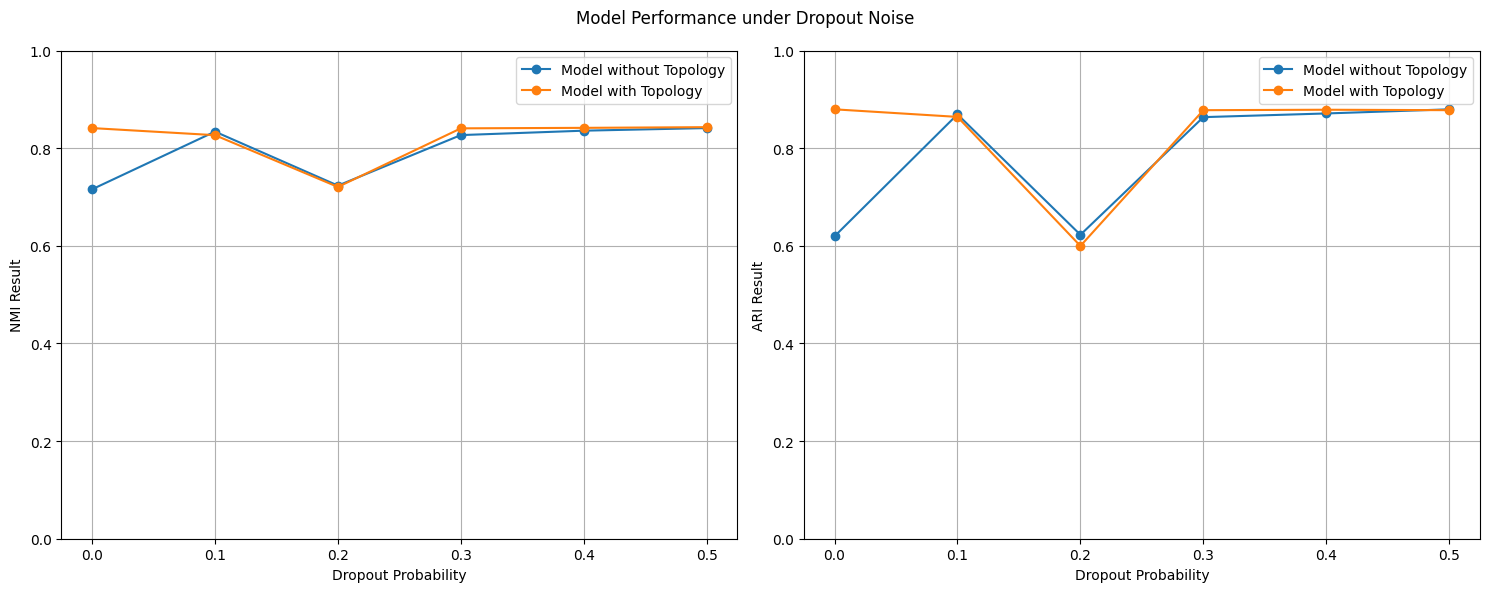

In [26]:
from utils.perturbation import dropout_event

# Testing with dropout_event first
drop_prob = np.arange(0, 0.55, 0.1)

nmi_scores_1 = []
nmi_scores_2 = []
ari_scores_1 = []
ari_scores_2 = []

for prob in drop_prob:
    x_noisy = dropout_event(x_data, prob)
    data = Data(x=torch.from_numpy(X), y=torch.tensor(Y, dtype=torch.int64))
    cellGraph=GraphConstruction(data, X, NUM_CLUSTERS)
    adj_graph_clone = edge2adj(x_data, data.edge_index)

    nmi_1, ari_1 = train_model(data, cellGraph, use_topo=False)
    nmi_2, ari_2 = train_model(data, cellGraph, use_topo=True)

    print(f"Dropout Noise Level: {prob:.2f} | Model 1 NMI: {nmi_1:.4f} | Model 1 ARI: {ari_1:.4f} | Model 2 NMI: {nmi_2:.4f} | Model 2 ARI: {ari_2:.4f}")

    nmi_scores_1.append(nmi_1)
    nmi_scores_2.append(nmi_2)
    ari_scores_1.append(ari_1)
    ari_scores_2.append(ari_2)

import matplotlib.pyplot as plt

plt.figure(figsize=(15, 6))

plt.subplot(1, 2, 1)
plt.plot(drop_prob, nmi_scores_1, marker='o', label='Model without Topology')
plt.plot(drop_prob, nmi_scores_2, marker='o', label='Model with Topology')
plt.xlabel('Dropout Probability')
plt.ylabel('NMI Result')
plt.ylim(0, 1)
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(drop_prob, ari_scores_1, marker='o', label='Model without Topology')
plt.plot(drop_prob, ari_scores_2, marker='o', label='Model with Topology')
plt.xlabel('Dropout Probability')
plt.ylabel('ARI Result')
plt.ylim(0, 1)
plt.legend()
plt.grid()

plt.suptitle('Model Performance under Dropout Noise')
plt.tight_layout()

plt.show()

### B. Testing robustness with Gaussian noise in `X_data`

Building a Graph with 870 nodes and 9577 edges
Epoch=000, loss1=6.1300, loss2=6.1968, loss3=0.0000, total loss=12.3268, total time 0.1744
Epoch=000, loss1=5.5526, loss2=5.7493, loss3=0.0000, total loss=11.3019, total time 0.1560
Epoch=000, loss1=6.1342, loss2=6.2017, loss3=0.0000, total loss=12.3359, total time 0.3680
Epoch=000, loss1=5.5806, loss2=6.0731, loss3=1.4810, total loss=13.1348, total time 0.2632
Gaussian Noise Mean: 0.00 | Model 1 NMI: 0.8302 | Model 1 ARI: 0.8710 | Model 2 NMI: 0.8156 | Model 2 ARI: 0.8514
Building a Graph with 870 nodes and 9577 edges
Epoch=000, loss1=6.1257, loss2=6.2072, loss3=0.0000, total loss=12.3329, total time 0.1545
Epoch=000, loss1=5.5530, loss2=6.0434, loss3=0.0000, total loss=11.5965, total time 0.1551
Epoch=000, loss1=6.1194, loss2=6.2193, loss3=0.0000, total loss=12.3386, total time 0.3381
Epoch=000, loss1=5.5467, loss2=5.9301, loss3=1.6041, total loss=13.0810, total time 0.2610
Gaussian Noise Mean: 0.10 | Model 1 NMI: 0.8411 | Model 1 ARI: 0

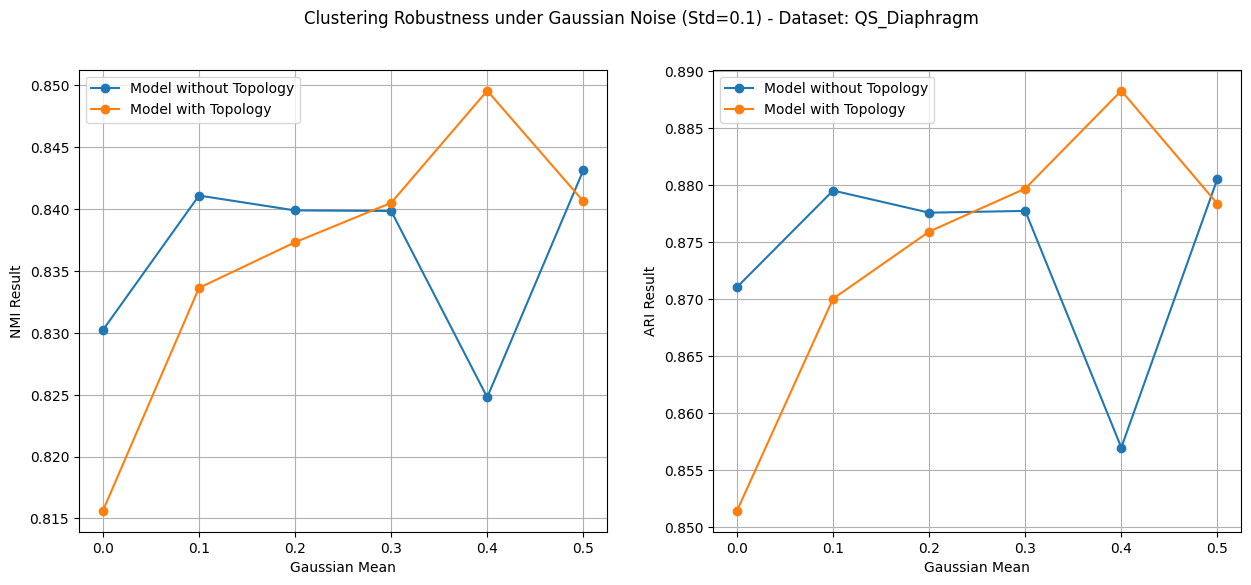

In [28]:
from utils.perturbation import gaussian_noise_event

# Testing with dropout_event first
STD_GAUSSIAN = 0.1
gaussian_mean = np.arange(0, 0.55, 0.1)

nmi_scores_1 = []
nmi_scores_2 = []
ari_scores_1 = []
ari_scores_2 = []

for mean in gaussian_mean:
    x_noisy = gaussian_noise_event(x_data, mean, std=STD_GAUSSIAN)
    data = Data(x=torch.from_numpy(X), y=torch.tensor(Y, dtype=torch.int64))
    cellGraph=GraphConstruction(data, X, NUM_CLUSTERS)
    adj_graph_clone = edge2adj(x_data, data.edge_index)

    nmi_1, ari_1 = train_model(data, cellGraph, use_topo=False)
    nmi_2, ari_2 = train_model(data, cellGraph, use_topo=True)

    print(f"Gaussian Noise Mean: {mean:.2f} | Model 1 NMI: {nmi_1:.4f} | Model 1 ARI: {ari_1:.4f} | Model 2 NMI: {nmi_2:.4f} | Model 2 ARI: {ari_2:.4f}")

    nmi_scores_1.append(nmi_1)
    nmi_scores_2.append(nmi_2)
    ari_scores_1.append(ari_1)
    ari_scores_2.append(ari_2)

import matplotlib.pyplot as plt

plt.figure(figsize=(15, 6))

plt.subplot(1, 2, 1)
plt.plot(gaussian_mean, nmi_scores_1, marker='o', label='Model without Topology')
plt.plot(gaussian_mean, nmi_scores_2, marker='o', label='Model with Topology')
plt.xlabel('Gaussian Mean')
plt.ylabel('NMI Result')
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(gaussian_mean, ari_scores_1, marker='o', label='Model without Topology')
plt.plot(gaussian_mean, ari_scores_2, marker='o', label='Model with Topology')
plt.xlabel('Gaussian Mean')
plt.ylabel('ARI Result')
plt.legend()
plt.grid()

plt.suptitle(f'Clustering Robustness under Gaussian Noise (Std={STD_GAUSSIAN}) - Dataset: {dataset}')
plt.show()

### C. Testing robustness with Edge Dropping

Epoch=000, loss1=6.1085, loss2=6.2038, loss3=0.0000, total loss=12.3123, total time 0.1892
Epoch=000, loss1=5.5792, loss2=5.8227, loss3=0.0000, total loss=11.4019, total time 0.1492
Epoch=000, loss1=6.0985, loss2=6.1799, loss3=0.0000, total loss=12.2784, total time 0.3480
Epoch=000, loss1=5.6284, loss2=6.1261, loss3=2.0321, total loss=13.7866, total time 0.2558
Dropout Edge Level: 0.00 | Model 1 NMI: 0.8389 | Model 1 ARI: 0.8766 | Model 2 NMI: 0.8289 | Model 2 ARI: 0.8692
Epoch=000, loss1=6.0662, loss2=6.1567, loss3=0.0000, total loss=12.2228, total time 0.3257
Epoch=000, loss1=5.5769, loss2=6.1273, loss3=0.0000, total loss=11.7041, total time 0.2169
Epoch=000, loss1=6.0962, loss2=6.1854, loss3=0.0000, total loss=12.2816, total time 0.3670
Epoch=000, loss1=5.6304, loss2=5.9443, loss3=1.8788, total loss=13.4534, total time 0.2552
Dropout Edge Level: 0.05 | Model 1 NMI: 0.8298 | Model 1 ARI: 0.8670 | Model 2 NMI: 0.8489 | Model 2 ARI: 0.8891
Epoch=000, loss1=6.0733, loss2=6.1768, loss3=0

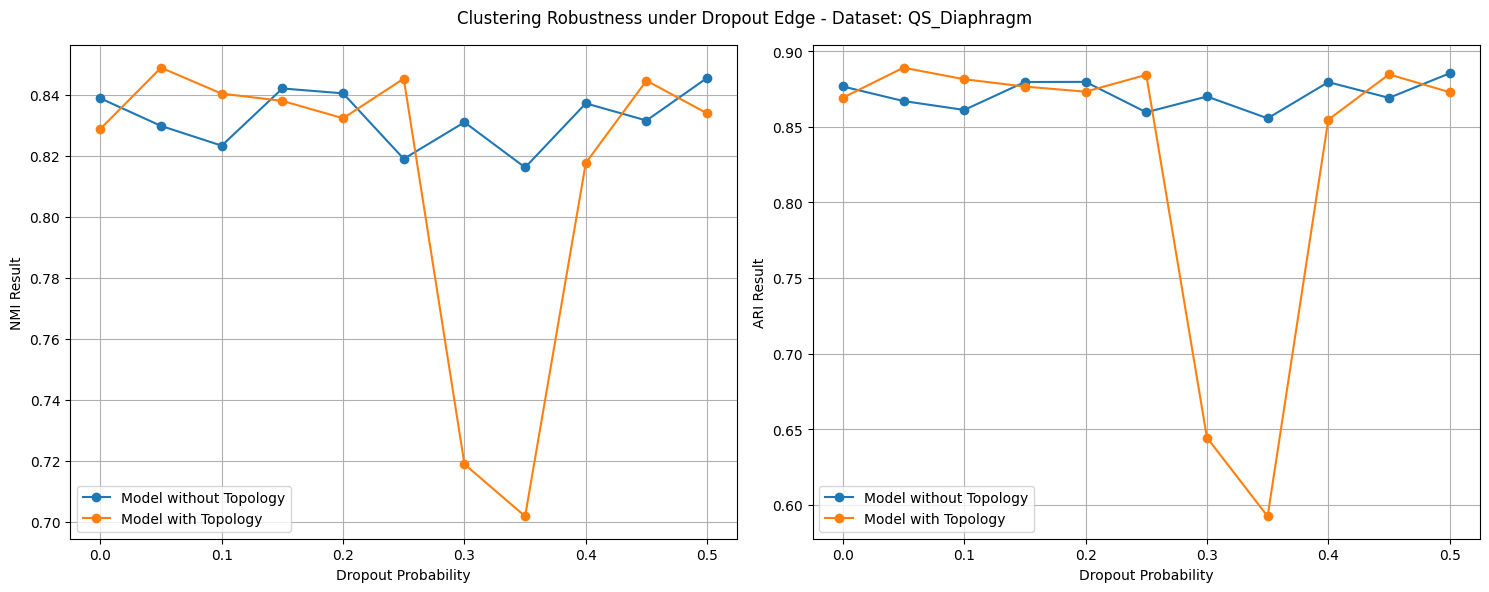

In [ ]:
from utils.perturbation import edge_dropout_event

# Testing with dropout_event first
edge_drop_prob = np.arange(0, 0.55, 0.1)

nmi_scores_1 = []
nmi_scores_2 = []
ari_scores_1 = []
ari_scores_2 = []

for prob in edge_drop_prob:
    noise_adj_graph, _ = edge_dropout_event(edge_index=edge_idx, drop_prob=prob, force_undirected=True)
    adj_noisy = edge2adj(x_noisy, noise_adj_graph)
    cellGraph_noisy = nx.from_numpy_array(adj_noisy.to_dense().cpu().numpy())

    nmi_1, ari_1 = train_model(data, cellGraph_noisy, use_topo=False)
    nmi_2, ari_2 = train_model(data, cellGraph_noisy, use_topo=True)

    nmi_scores_1.append(nmi_1)
    ari_scores_1.append(ari_1)
    nmi_scores_2.append(nmi_2)
    ari_scores_2.append(ari_2)
    print(f"Dropout Edge Level: {prob:.2f} | Model 1 NMI: {nmi_1:.4f} | Model 1 ARI: {ari_1:.4f} | Model 2 NMI: {nmi_2:.4f} | Model 2 ARI: {ari_2:.4f}")

import matplotlib.pyplot as plt

plt.figure(figsize=(15, 6))

plt.subplot(1, 2, 1)
plt.plot(edge_drop_prob, nmi_scores_1, marker='o', label='Model without Topology')
plt.plot(edge_drop_prob, nmi_scores_2, marker='o', label='Model with Topology')
plt.xlabel('Dropout Probability')
plt.ylabel('NMI Result')
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(edge_drop_prob, ari_scores_1, marker='o', label='Model without Topology')
plt.plot(edge_drop_prob, ari_scores_2, marker='o', label='Model with Topology')
plt.xlabel('Dropout Probability')
plt.ylabel('ARI Result')
plt.legend()
plt.grid()

plt.suptitle(f'Clustering Robustness under Dropout Edge - Dataset: {dataset}')

plt.tight_layout()
plt.show()